# **Experiments**

The pipeline notebook (`05_routing_pipeline.ipynb`) is run for every experiment. Each run changes one parameter with respect to a base case ($N$ = 200 and $N$ = 1,000) and keeps everything else as in the pipeline.

Every point is run with the seeds 42–46, which draw the requests, their tiers and the draws of the Random baseline. An energy is compared only between feasible solutions, seed by seed.

Every finished run is written at once to `EXP_DIR`; when the notebook is run again, finished runs are skipped. Outputs: `runs.csv` (one row per run), `methods.csv` (FL-MILP and every baseline, per run), `models.csv` (one row per model and run), `logs/`, tables and plots.

## Install

In [1]:
!pip install -q "pulp==2.9.0" pyarrow

## Configuration

In [4]:
import contextlib
import hashlib
import io
import json
import os
import time
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PIPELINE_NOTEBOOK_PATH = "05_routing_pipeline.ipynb"
EXP_DIR = "results/experiments"
RUN_OUTPUT_DIR = "/tmp/experiment_run_files"   # files written by the pipeline notebook itself (not kept)

BASE_N = [200, 1000]        # base cases of every experiment except E7
SEEDS = [42, 43, 44, 45, 46]    # finished runs are skipped
RETRY_FAILED = False        # True: run again the runs that ended with an error
PATH_REPLACEMENTS = {}      # {"path in the pipeline": "new path"}

P0_W = 71.8                 # H100 on, no model loaded (Vadari 2026): parking power = P0 + parking tax
LLAMA_8B = "meta-llama/llama-3.1-8b-instruct"
LLAMA_33_70B = "meta-llama/llama-3.3-70b-instruct"

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

## Pipeline notebook

In [5]:
os.makedirs(os.path.join(EXP_DIR, "logs"), exist_ok=True)
os.makedirs(RUN_OUTPUT_DIR, exist_ok=True)
assert os.path.exists(PIPELINE_NOTEBOOK_PATH), f"pipeline notebook not found: {PIPELINE_NOTEBOOK_PATH}"

pipeline_code = ["".join(c["source"]) for c in json.load(open(PIPELINE_NOTEBOOK_PATH))["cells"] if c["cell_type"] == "code"]
pipeline_code = [s for s in pipeline_code if not s.lstrip().startswith("!pip")]
assert any("REFERENCE_TIER_RATIO" in s for s in pipeline_code), "the pipeline notebook does not compute the budget of the batch"
for old, new in PATH_REPLACEMENTS.items():
    pipeline_code = [s.replace(old, new) for s in pipeline_code]

def find_cell(cells, marker):
    hits = [k for k, s in enumerate(cells) if marker in s]
    assert len(hits) == 1, f"marker {marker!r} found in {len(hits)} cells of the pipeline notebook (expected 1)"
    return hits[0]

CONFIG_CELL = find_cell(pipeline_code, "rng = np.random.default_rng(SEED)")
SOLVE_CELL = find_cell(pipeline_code, "status, culprits = solve(prob, K")
print(f"pipeline notebook: {len(pipeline_code)} code cells")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
v9 notebook: 50 code cells


## The experiments

A run = base case + overrides + seed. The same configuration reached from two experiments is run once.

In [ ]:
def park(w):            # parking tax above P0, in W per GPU
    return {"H100_IDLE_WITH_MODEL_W": round(P0_W + w, 3)}

STRICT = {"TIER_RATIO": {"Economy": 0.60, "Standard": 0.85, "Premium": 0.98}}
def health(share=1.0):      # specialization: only the batch changes, everything else as in the base case
    return {"SUBJECT_FOCUS": "health", "SUBJECT_FOCUS_SHARE": share}

LLAMA3_ONLY = ["meta-llama/llama-3.1-8b-instruct", "meta-llama/llama-3.1-70b-instruct", "meta-llama/llama-3.3-70b-instruct",
               "nvidia/llama-3.1-nemotron-70b-instruct-hf", "nvidia/openmath2-llama3.1-8b"]   # left out: all based on Llama-3.1

def specialist(ratio, share=1.0):
    return {**health(share), "HYPOTHETICAL_SPECIALIST": {"donor": LLAMA_8B, "subject": "health", "quality_ratio": ratio}}

EXPERIMENTS = [
    ("E7", "requests N", [(f"N = {n}", {"N_REQUESTS": n}) for n in [200, 500, 1000, 2000, 4000]]),
    ("P", "parking power", [("0 W", park(0)), ("25 W", park(25)), ("49.9 W (base)", park(49.9))]),
    ("E1", "budget margin delta on C_min of the batch", [(f"{m:.0%}" + (" (base)" if m == 0.20 else ""), {"BUDGET_MARGIN": m})
                                      for m in [0.0, 0.05, 0.10, 0.15, 0.20]]),
    ("E3a", "TIER_RATIO", [
        ("0.30/0.50/0.80", {"TIER_RATIO": {"Economy": 0.30, "Standard": 0.50, "Premium": 0.80}}),
        ("0.40/0.65/0.90", {"TIER_RATIO": {"Economy": 0.40, "Standard": 0.65, "Premium": 0.90}}),
        ("0.50/0.75/0.95 (base)", {"TIER_RATIO": {"Economy": 0.50, "Standard": 0.75, "Premium": 0.95}}),
        ("0.60/0.85/0.98", STRICT)]),
    ("E3b", "TIER_MIX", [
        ("20/60/20 (base)", {"TIER_MIX": {"Economy": 0.2, "Standard": 0.6, "Premium": 0.2}}),
        ("80/10/10", {"TIER_MIX": {"Economy": 0.8, "Standard": 0.1, "Premium": 0.1}}),
        ("10/30/60", {"TIER_MIX": {"Economy": 0.1, "Standard": 0.3, "Premium": 0.6}})]),
    ("E2", "period T", [(f"{m} min" + (" (base)" if m == 10 else ""), {"WORKLOAD_DURATION_S": 60 * m})
                               for m in [1, 2, 5, 10, 20, 30]]),
    ("BC", "batch capacity", [(f"{b}" + (" (base)" if b == 128 else ""), {"BATCH": b}) for b in [32, 64, 128, 512]]),
    ("E6", "models already loaded", [("none (base)", {"ALREADY_ACTIVE": []}), ("8B", {"ALREADY_ACTIVE": [LLAMA_8B]}),
                                     ("Llama-3.3-70B", {"ALREADY_ACTIVE": [LLAMA_33_70B]}),
                                     ("both", {"ALREADY_ACTIVE": [LLAMA_8B, LLAMA_33_70B]})]),
    ("SP", "specialists of the pool, health requests", [("health, base thresholds", health()),
                                                        ("health, strict thresholds", {**health(), **STRICT})]),
    ("HS", "hypothetical 8B health specialist", [("health only, no specialist", health())]
           + [(f"health only, {r:.0%} of best", specialist(r)) for r in [0.70, 0.80, 0.90, 0.95, 1.00]]
           + [("half health, no specialist", health(0.5))]
           + [(f"half health, {r:.0%} of best", specialist(r, 0.5)) for r in [0.80, 0.90, 1.00]]),
    ("SPL3", "medical specialists against their own base model (Llama-3 pool), health requests", [
        ("health, base thresholds", {**health(), "EXCLUDE_MODELS": LLAMA3_ONLY}),
        ("health, strict thresholds", {**health(), **STRICT, "EXCLUDE_MODELS": LLAMA3_ONLY}),
        ("half health", {**health(0.5), "EXCLUDE_MODELS": LLAMA3_ONLY})]),
    ("S", "sensitivity", [("base", {}),
                          ("weights 0.3/0.7", {"W_DOMAIN": 0.3, "W_TASK": 0.7}),
                          ("weights 0.7/0.3", {"W_DOMAIN": 0.7, "W_TASK": 0.3}),
                          ("alpha 0.25", {"ALPHA_COMPLEXITY": 0.25}), ("alpha 0.75", {"ALPHA_COMPLEXITY": 0.75}),
                          ("rho 50", {"INPUT_OUTPUT_RATIO": 50}), ("rho 300", {"INPUT_OUTPUT_RATIO": 300})]),
]

# default values of the pipeline configuration: an override equal to the default is dropped, so that the same
# configuration always gets the same identifier (e.g. "parking 49.9 W" of experiment P = the base case).
_defaults = {"np": np, "pd": pd}
exec(compile(pipeline_code[CONFIG_CELL], "pipeline_config", "exec"), _defaults)

def normalise(config):
    return {k: v for k, v in config.items() if k not in _defaults or _defaults[k] != v}

NO_BASE = {"E7"}      # experiments that set N themselves

def run_id(config):
    return hashlib.md5(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]

plan = []        # one row per (experiment, value, base, seed); several rows can share the same run
for exp, parameter, values in EXPERIMENTS:
    bases = [None] if exp in NO_BASE else BASE_N
    for label, overrides in values:
        for base_n in bases:
            for seed in SEEDS:
                full = {"N_REQUESTS": base_n, **overrides, "SEED": seed} if base_n else {**overrides, "SEED": seed}
                config = normalise(full)
                plan.append({"experiment": exp, "parameter": parameter, "value": label,
                             "base_N": base_n if base_n else "own", "seed": seed,
                             "run_id": run_id(config), "config": config})
plan = pd.DataFrame(plan)
runs_to_do = plan.drop_duplicates("run_id")
print(f"{len(plan)} points of the experiments, {len(runs_to_do)} distinct runs")
print(plan.groupby("experiment", sort=False)["run_id"].nunique().rename("distinct runs").to_string())

535 points of the experiments, 445 distinct runs
experiment
E7       25
P        30
E1       50
E3a      40
E3b      30
E2       60
BC       40
E6       40
SP       20
HS      100
SPL3     30
S        70


## Running the pipeline notebook and collecting the results

The configuration lines of a run are inserted in the configuration cell of the pipeline, which is run in a clean namespace. A run that fails is recorded with its error; its printed output goes to `logs/`.

In [7]:
RUNS_CSV, METHODS_CSV, MODELS_CSV = (os.path.join(EXP_DIR, f) for f in ["runs.csv", "methods.csv", "models.csv"])

def patched(config, rid):
    cells = list(pipeline_code)
    lines = [f"{k} = {v!r}" for k, v in config.items()] + [f"OUTPUT_DIR = {os.path.join(RUN_OUTPUT_DIR, rid)!r}"]
    cells[CONFIG_CELL] = cells[CONFIG_CELL].replace(
        "rng = np.random.default_rng(SEED)",
        "# --- experiments ---\n" + "\n".join(lines) + "\nrng = np.random.default_rng(SEED)")
    return cells

def append(path, rows):
    pd.DataFrame(rows).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def collect(rid, config, ns, seconds, solve_seconds):
    comp, short, n_assigned = ns["comp"], ns["short"], ns["n_assigned"]
    milp = comp.loc["Facility-location MILP"]
    single_name = [m for m in comp.index if m.startswith("Single model")][0]
    single = comp.loc[single_name]
    both_feasible = bool(single["feasible"]) and bool(milp["feasible"])
    hs_key = ns.get("HS_KEY")
    run_row = {
        "run_id": rid, "config": json.dumps(config, sort_keys=True), "status": "ok",
        "N": ns["N"], "distinct_requests": int(ns["workload"]["source_request_id"].nunique()),
        "seconds": round(seconds, 1), "solver_seconds": round(solve_seconds, 1),
        "energy_kJ": float(milp["total_energy_kJ"]), "activation_kJ": float(milp["activation_kJ"]),
        "serving_kJ": float(milp["serving_kJ"]), "parking_kJ": float(milp["parking_kJ"]),
        "energy_reference_length_kJ": float(milp["energy_reference_length_kJ"]),
        "cost_usd": float(milp["cost_usd"]), "budget_usd": ns["B"], "C_min_usd": ns["C_min"],
        "cheapest_cost_usd": ns["CHEAPEST_COST_USD"], "C_max_usd": ns["C_max"],
        "mean_quality": float(milp["mean_quality"]), "models": int(round(float(milp["models"]))),
        "gpus": int(round(float(milp["gpus"]))), "to_specialists": float(milp["to_specialists"]),
        "max_utilisation": float(milp["max_utilisation"]),
        "milp_feasible": int(bool(milp["feasible"])), "milp_optimal": int(ns["MILP_STATUS"] == "optimal"),
        "milp_status": ns["MILP_STATUS"],
        "milp_violates": milp["violates"],
        "active": ", ".join(f"{short(j)} ({int(n_assigned[j])})" for j in ns["M_star"]),
        "hypothetical_assigned": int(n_assigned[hs_key]) if hs_key else np.nan,
        "single_model": single_name.replace("Single model: ", ""),
        "single_model_energy_kJ": float(single["total_energy_kJ"]), "single_model_cost_usd": float(single["cost_usd"]),
        "single_model_feasible": int(bool(single["feasible"])), "single_model_violates": single["violates"],
        "routing_saving_%": (100 * (float(single["total_energy_kJ"]) - float(milp["total_energy_kJ"])) / float(single["total_energy_kJ"])
                             if both_feasible else np.nan),
        "lower_bound_kJ": ns["E_LB_kJ"],
        "preparation_s": ns["PREPARATION_SECONDS"], "budget_s": ns["BUDGET_SECONDS"],
        "milp_build_s": ns["MILP_BUILD_SECONDS"], "milp_solve_s": ns["MILP_SOLVE_SECONDS"],
        "lower_bound_s": ns["LOWER_BOUND_SECONDS"],
    }
    method_rows = [{"run_id": rid, "method": m.split(":")[0], "single_model": m.split(": ")[1] if ": " in m else "",
                    "energy_kJ": float(r["total_energy_kJ"]), "cost_usd": float(r["cost_usd"]),
                    "mean_quality": float(r["mean_quality"]), "models": float(r["models"]), "gpus": float(r["gpus"]),
                    "to_specialists": float(r["to_specialists"]), "max_utilisation": float(r["max_utilisation"]),
                    "quality_ok": float(r["quality_ok"]), "budget_ok": float(r["budget_ok"]), "capacity_ok": float(r["capacity_ok"]),
                    "feasible": int(bool(r["feasible"])), "violates": r["violates"],
                    "not_eligible_requests": float(r["not_eligible_requests"]),
                    "energy_vs_MILP_%": float(r["energy_vs_MILP_%"]), "gap_to_LB_%": float(r["gap_to_LB_%"]),
                    "decision_time_s": float(r["decision_time_s"]), "active": r["active"]} for m, r in comp.iterrows()]
    Q, elig, E_srv, c, F = ns["Q"], ns["eligible"], ns["E_srv"], ns["c"], ns["F"]
    model_rows = [{"run_id": rid, "model": short(j), "role": ns["models"].loc[j, "role"], "mean_quality": float(Q[j].mean()),
                   "eligible_for": int(elig[j].sum()), "mean_serving_J": float(E_srv[j].mean()),
                   "fixed_energy_kJ": float(F[j]) / 1e3, "activation_kJ": float(ns["e_act"][j]) / 1e3,
                   "mean_cost_usd": float(c[j].mean()), "active": int(j in ns["M_star"]),
                   "requests_assigned": int(n_assigned[j])} for j in ns["MODEL_IDS"]]
    return run_row, method_rows, model_rows

def run_once(rid, config):
    ns, log, error = {}, io.StringIO(), None
    start = time.time()
    solve_seconds = 0.0
    with contextlib.redirect_stdout(log):
        try:
            for k, src in enumerate(patched(config, rid)):
                t0 = time.time()
                exec(compile(src, f"pipeline_cell_{k}", "exec"), ns)
                if k == SOLVE_CELL:
                    solve_seconds = time.time() - t0
        except Exception:
            error = traceback.format_exc()
    seconds = time.time() - start
    plt.close("all")
    if error:
        with open(os.path.join(EXP_DIR, "logs", f"{rid}.log"), "w") as f:
            f.write(json.dumps(config) + "\n\n" + log.getvalue() + "\n" + error)
        append(RUNS_CSV, [{"run_id": rid, "config": json.dumps(config, sort_keys=True),
                           "status": "error: " + error.strip().splitlines()[-1][:200],
                           "N": config.get("N_REQUESTS", 200), "seconds": round(seconds, 1)}])
        return "error: " + error.strip().splitlines()[-1][:120]
    run_row, method_rows, model_rows = collect(rid, config, ns, seconds, solve_seconds)
    append(RUNS_CSV, [run_row])
    append(METHODS_CSV, method_rows)
    append(MODELS_CSV, model_rows)
    saving = run_row["routing_saving_%"]
    return (f"{run_row['active']} | {run_row['energy_kJ']:.1f} kJ | {run_row['milp_status']} | "
            + (f"saving vs single {saving:.2f}%" if pd.notna(saving) else f"single model infeasible ({run_row['single_model_violates']})"))

def done_ids():
    if not os.path.exists(RUNS_CSV):
        return set()
    r = pd.read_csv(RUNS_CSV, on_bad_lines="skip")
    keep = r if not RETRY_FAILED else r[r["status"] == "ok"]
    return set(keep["run_id"])

def run_experiments(experiments):
    todo = plan[plan["experiment"].isin(experiments)].drop_duplicates("run_id")
    already = done_ids()
    todo = todo[~todo["run_id"].isin(already)]
    print(f"{len(todo)} runs to do ({len(already)} already done)")
    start = time.time()
    for n, (_, p) in enumerate(todo.iterrows(), 1):
        outcome = run_once(p["run_id"], p["config"])
        elapsed = time.time() - start
        print(f"[{n}/{len(todo)}] {p['experiment']} | {p['value']} | N {p['base_N']} | seed {p['seed']} | {outcome} "
              f"| {elapsed / 60:.1f} min, about {elapsed / n * (len(todo) - n) / 60:.0f} min left")

## Run E7 (number of requests)

In [ ]:
run_experiments(["E7"])

## Run the other experiments

After a disconnection, run the setup cells again and then this cell: finished runs are skipped.

In [ ]:
run_experiments(["P", "E1", "E3a", "E3b", "E2", "BC", "SP", "HS", "SPL3", "E6", "S"])

## Results by experiment

One row per value and base case. Quantities of the FL-MILP solution are averaged only over the seeds in which it is feasible; `infeasible_kJ` (infeasible, diagnostic solutions) is not comparable with `energy_kJ`.

In [8]:
import re

def load_all():
    runs = pd.read_csv(RUNS_CSV, on_bad_lines="skip").drop_duplicates("run_id", keep="last")
    methods = pd.read_csv(METHODS_CSV, on_bad_lines="skip").drop_duplicates(["run_id", "method"], keep="last")
    res = plan.merge(runs.drop(columns=["config"]), on="run_id", how="left")
    res["ok"] = res["status"] == "ok"
    meth = plan.merge(methods, on="run_id", how="inner")
    n_requests = pd.to_numeric(runs.set_index("run_id")["N"])
    meth["quality_met"] = 1 - meth["not_eligible_requests"] / meth["run_id"].map(n_requests)   # share of requests meeting their threshold
    return res, meth

def kinds(*violates):
    # letters of the constraints violated in one or more runs: Q quality, B budget, C capacity
    v = " ".join(str(x) for x in violates if pd.notna(x))
    return ",".join(k[0].upper() for k in ["quality", "budget", "capacity"] if k in v)

def frac(x, n=None):
    n = len(x) if n is None else n
    return f"{int(x.sum())}/{n}" if n else "-"

def selections(ok):
    # distinct sets of active models over the seeds, with their frequency (request counts removed)
    def one(r):
        models = re.sub(r" \(\d+\)", "", str(r["active"]))
        if r["milp_feasible"] != 1:
            return models + " [infeasible]"
        return models + ("" if r["milp_optimal"] == 1 else " [not proven optimal]")
    counts = ok.apply(one, axis=1).value_counts()
    return "; ".join(f"{k} x{v}" for k, v in counts.items())

def experiment_table(res, exp):
    part = res[res["experiment"] == exp]
    order = list(dict.fromkeys(part["value"]))
    rows = []
    for (value, base_n), g in part.groupby(["value", "base_N"], sort=False):
        ok = g[g["ok"]]
        fe = ok[ok["milp_feasible"] == 1]          # feasible MILP solutions: the only ones averaged
        inf = ok[ok["milp_feasible"] != 1]         # infeasible: diagnostic energy, reported apart
        s_ok = ok["single_model_feasible"] == 1
        rows.append({
            "value": value, "base_N": base_n, "runs_ok": f"{len(ok)}/{len(g)}",
            "milp_feasible": frac(ok["milp_feasible"]), "milp_optimal": frac(ok["milp_optimal"]),
            "energy_kJ": fe["energy_kJ"].mean(), "energy_sd": fe["energy_kJ"].std(),
            "infeasible_kJ": inf["energy_kJ"].mean() if len(inf) else np.nan,
            "single_ok": frac(s_ok), "single_kJ": ok.loc[s_ok, "single_model_energy_kJ"].mean(),
            "single_violates": kinds(*ok.loc[~s_ok, "single_model_violates"]),
            "saving_%": ok["routing_saving_%"].mean(), "saving_sd": ok["routing_saving_%"].std(),
            "models": fe["models"].mean(), "gpus": fe["gpus"].mean(), "quality": fe["mean_quality"].mean(),
            "cost_usd": fe["cost_usd"].mean(), "budget_usd": ok["budget_usd"].mean(),
            "room_%": (100 * (ok["budget_usd"] / ok["cheapest_cost_usd"] - 1)).min(),
            "max_util": fe["max_utilisation"].mean(), "to_spec": fe["to_specialists"].mean(),
            "selections": selections(ok) if len(ok) else str(g["status"].iloc[0])[:80],
        })
    t = pd.DataFrame(rows)
    t["value"] = pd.Categorical(t["value"], order, ordered=True)
    return t.sort_values(["base_N", "value"]).set_index(["base_N", "value"])

res, meth = load_all()
tables = {}
for exp, parameter, _ in EXPERIMENTS:
    if not res.loc[res["experiment"] == exp, "ok"].any():
        print(f"\n{exp}: not run yet")
        continue
    tables[exp] = experiment_table(res, exp)
    print(f"\n=== {exp}: {parameter}")
    print(tables[exp].round(3).to_string())
    tables[exp].to_csv(os.path.join(EXP_DIR, f"table_{exp}.csv"))



=== E7: requests N
                runs_ok milp_feasible milp_optimal  energy_kJ  energy_sd  infeasible_kJ single_ok  single_kJ single_violates  saving_%  saving_sd  models  gpus  quality  cost_usd  budget_usd  room_%  max_util  to_spec                                                                                                                  selections
base_N value                                                                                                                                                                                                                                                                                                                                         
own    N = 200      5/5           5/5          5/5    173.481      2.382            NaN       5/5    173.481                     0.000      0.000     1.0   4.0    0.540     0.040       0.042    20.0     0.123      0.0                                                                               

## Plots: every method and the trade-off of each experiment

One row of panels per base case: energy of every method; FL-MILP and single model only; the quantity the experiment changes. Lines for ordered parameters, bars for distinct scenarios. `k/n` marks a mean over `k` of the `n` seeds; hollow markers and hatched bars: feasible in no seed.

In [9]:
STYLE = {
    "Facility-location MILP": dict(color="C0", marker="o", lw=2.0, ls="-"),
    "Greedy facility location": dict(color="C1", marker="s", lw=1.4, ls="--"),
    "Single model": dict(color="C2", marker="D", lw=1.4, ls="-"),
    "Cost-First": dict(color="C3", marker="^", lw=1.2, ls="-"),
    "Quality-First": dict(color="C4", marker="v", lw=0.8, ls=":"),
    "Energy-First (per request)": dict(color="C5", marker="<", lw=0.8, ls=":"),
    "Random (mean of 300)": dict(color="C7", marker="P", lw=0.8, ls=":"),
}
LINE_EXPERIMENTS = {"E7", "P", "E1", "E2", "BC"}     # ordered numeric parameter: lines; the others are distinct scenarios: bars
TRADEOFF = {"E7": ["models"], "P": ["models"], "E1": ["cost_usd"], "E3a": ["quality_met"], "E3b": ["quality_met"],
            "E2": ["max_utilisation"], "BC": ["max_utilisation", "models"], "E6": ["models"], "SP": ["to_specialists", "cost_usd"],
            "HS": ["to_specialists", "cost_usd"], "SPL3": ["to_specialists", "cost_usd"], "S": ["models"]}
LABEL = {"energy_kJ": "energy (kJ)", "models": "active models", "cost_usd": "cost (USD)",
         "quality_met": "share of requests meeting their quality threshold",
         "max_utilisation": "largest share of the period used", "to_specialists": "share of requests to specialists"}
METRICS = ["energy_kJ", "cost_usd", "quality_met", "models", "max_utilisation", "to_specialists"]

def group_of(value):        # specialization: the half-health batch is a different batch, shown as a separate group
    return "half health" if "half health" in str(value) else ""

def method_means(meth, exp, base_n):
    # per method and value: mean over the feasible seeds (and the feasible values themselves, for the dots);
    # if no seed is feasible, mean of the infeasible (diagnostic) runs
    part = meth[(meth["experiment"] == exp) & (meth["base_N"] == base_n)]
    order = list(dict.fromkeys(plan.loc[(plan["experiment"] == exp), "value"]))
    rows = []
    for (m, v), g in part.groupby(["method", "value"]):
        fe = g[g["feasible"] >= 1]
        use = fe if len(fe) else g
        # the share of requests meeting their threshold is shown over every seed: its point is to show the violations
        rows.append({"method": m, "value": v, "n_feasible": len(fe), "n": len(g),
                     **{k: (g if k == "quality_met" else use)[k].mean() for k in METRICS},
                     **{f"{k}_seeds": list((g if k == "quality_met" else fe)[k]) for k in METRICS}})
    agg = pd.DataFrame(rows)
    return agg, [v for v in order if v in set(agg["value"])]

def positions(order):
    # x position of every value, with a gap between groups (health only / half health)
    x, pos, prev = 0.0, {}, None
    for v in order:
        if prev is not None and group_of(v) != prev:
            x += 0.6
        pos[v], prev = x, group_of(v)
        x += 1.0
    return pos

def draw_lines(ax, agg, order, metric, methods):
    x = {v: k for k, v in enumerate(order)}
    for m in methods:
        d = agg[agg["method"] == m].copy()
        if d.empty:
            continue
        d["x"] = d["value"].map(x)
        d = d.sort_values("x")
        st = STYLE[m]
        f = d["n_feasible"] > 0
        ax.plot(d.loc[f, "x"], d.loc[f, metric], color=st["color"], lw=st["lw"], ls=st["ls"], alpha=0.8)
        ax.scatter(d.loc[f, "x"], d.loc[f, metric], color=st["color"], marker=st["marker"], s=36, zorder=3)
        ax.scatter(d.loc[~f, "x"], d.loc[~f, metric], facecolors="none", edgecolors=st["color"], marker=st["marker"], s=36, zorder=3)
        for _, r in d[f & (d["n_feasible"] < d["n"])].iterrows():      # feasible only in some seeds
            ax.annotate(f"{int(r['n_feasible'])}/{int(r['n'])}", (r["x"], r[metric]), textcoords="offset points",
                        xytext=(4, 4), fontsize=6, color=st["color"])
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel(LABEL[metric], fontsize=8)

def draw_bars(ax, agg, order, metric, methods):
    pos = positions(order)
    present = [m for m in methods if (agg["method"] == m).any()]
    width = 0.8 / max(len(present), 1)
    for k, m in enumerate(present):
        d = agg[agg["method"] == m].set_index("value")
        st = STYLE[m]
        for v in order:
            if v not in d.index:
                continue
            r = d.loc[v]
            xb = pos[v] - 0.4 + width * (k + 0.5)
            feasible = r["n_feasible"] > 0
            ax.bar(xb, r[metric], width=width * 0.92, color=st["color"] if feasible else "none",
                   edgecolor=st["color"], hatch=None if feasible else "///", alpha=0.85 if feasible else 0.6, lw=0.8)
            seeds = r[f"{metric}_seeds"]
            if len(seeds) > 1:                   # single feasible seeds
                ax.scatter([xb] * len(seeds), seeds, s=6, color="k", zorder=3)
            if 0 < r["n_feasible"] < r["n"]:
                ax.annotate(f"{int(r['n_feasible'])}/{int(r['n'])}", (xb, r[metric]), textcoords="offset points",
                            xytext=(0, 3), ha="center", fontsize=5.5, color=st["color"])
    ax.set_xticks([pos[v] for v in order])
    ax.set_xticklabels(order, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel(LABEL[metric], fontsize=8)
    groups = list(dict.fromkeys(group_of(v) for v in order))
    if len(groups) > 1:                          # separator between the two batches
        first_half = min(pos[v] for v in order if group_of(v) == "half health")
        ax.axvline(first_half - 0.8, color="grey", lw=0.8, ls="--")

def experiment_plot(exp, parameter):
    bases = [b for b in (["own"] if exp in NO_BASE else BASE_N) if ((meth["experiment"] == exp) & (meth["base_N"] == b)).any()]
    if not bases:
        return
    draw = draw_lines if exp in LINE_EXPERIMENTS else draw_bars
    extra = TRADEOFF.get(exp, [])
    fig, axes = plt.subplots(len(bases), 2 + len(extra), figsize=(5.2 * (2 + len(extra)), 3.9 * len(bases)), squeeze=False)
    for r, base_n in enumerate(bases):
        agg, order = method_means(meth, exp, base_n)
        title = f"{exp}: {parameter}" + ("" if base_n == "own" else f", base N = {base_n}")
        draw(axes[r][0], agg, order, "energy_kJ", list(STYLE))
        axes[r][0].set_title(title + "\nall methods (mean over feasible seeds)", fontsize=8)
        draw(axes[r][1], agg, order, "energy_kJ", ["Facility-location MILP", "Single model"])
        axes[r][1].set_title("MILP and single model", fontsize=8)
        for k, metric in enumerate(extra):
            ax = axes[r][2 + k]
            draw(ax, agg, order, metric, list(STYLE))
            if metric == "cost_usd":
                b = res[(res["experiment"] == exp) & (res["base_N"] == base_n) & res["ok"]].groupby("value")["budget_usd"].mean()
                xs = list(range(len(order))) if draw is draw_lines else [positions(order)[v] for v in order]
                if draw is draw_lines:
                    ax.plot(xs, [b.get(v, np.nan) for v in order], color="k", ls=":", lw=1.5)
                else:                    # one budget per scenario: a dash over its bars, not a line between scenarios
                    ax.plot(xs, [b.get(v, np.nan) for v in order], color="k", ls="none", marker="_", ms=40, mew=1.5)
            if metric in ("max_utilisation", "quality_met"):
                ax.axhline(1.0, color="k", ls=":", lw=1.0)
            if metric == "quality_met":           # zoom: violations are often a few requests
                low = agg["quality_met"].min()
                ax.set_ylim(max(0.0, min(0.9, low - 0.02)), 1.005)
            ax.set_title(LABEL[metric], fontsize=8)
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    if draw is draw_lines:
        handles = [Line2D([], [], color=STYLE[m]["color"], ls=STYLE[m]["ls"], lw=STYLE[m]["lw"], marker=STYLE[m]["marker"], label=m)
                   for m in STYLE]
        handles += [Line2D([], [], color="grey", marker="o", ls="", label="feasible (k/n: only in k of n seeds)"),
                    Line2D([], [], color="grey", marker="o", ls="", markerfacecolor="none", label="feasible in no seed (diagnostic)")]
    else:
        handles = [Patch(facecolor=STYLE[m]["color"], edgecolor=STYLE[m]["color"], label=m) for m in STYLE]
        handles += [Patch(facecolor="none", edgecolor="grey", hatch="///", label="feasible in no seed (diagnostic)"),
                    Line2D([], [], color="k", marker="o", ms=3, ls="", label="feasible seeds (k/n: only in k of n)")]
    if "cost_usd" in extra:
        handles.append(Line2D([], [], color="k", ls=":", lw=1.5, label="budget B"))
    elif set(extra) & {"max_utilisation", "quality_met"}:
        handles.append(Line2D([], [], color="k", ls=":", lw=1.0, label="1 (whole period / every request)"))
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.12 / len(bases), 1, 1))
    fig.savefig(os.path.join(EXP_DIR, f"{exp}.png"), dpi=130)
    plt.show()

for exp, parameter, _ in EXPERIMENTS:
    if exp in tables:
        experiment_plot(exp, parameter)


Output hidden; open in https://colab.research.google.com to view.

## Every method, experiment by experiment

Energy (kJ) as `mean (k/n)` over the feasible seeds; in brackets, the energy of the infeasible seeds and the constraints they violate (Q quality, B budget, C capacity). Second table: energy against the FL-MILP (%), over the seeds in which both are feasible.

In [10]:
def method_tables(exp, base_n):
    part = meth[(meth["experiment"] == exp) & (meth["base_N"] == base_n)].copy()
    order = list(dict.fromkeys(plan.loc[plan["experiment"] == exp, "value"]))
    milp_ok = part[part["method"] == "Facility-location MILP"].set_index("run_id")["feasible"]
    part["milp_feasible"] = part["run_id"].map(milp_ok)
    rows, rel = {}, {}
    for (m, v), g in part.groupby(["method", "value"]):
        fe, inf = g[g["feasible"] >= 1], g[g["feasible"] < 1]
        cell = (f"{fe['energy_kJ'].mean():.1f}" if len(fe) else "-") + f" ({len(fe)}/{len(g)})"
        if len(inf):
            cell += f" [{inf['energy_kJ'].mean():.1f} x{kinds(*inf['violates'])}]"
        rows.setdefault(m, {})[v] = cell
        both = g[(g["feasible"] >= 1) & (g["milp_feasible"] >= 1)]
        rel.setdefault(m, {})[v] = both["energy_vs_MILP_%"].mean() if len(both) else np.nan
    cols = [v for v in order if v in set(part["value"])]
    idx = [m for m in STYLE if m in rows]
    return pd.DataFrame(rows).T.reindex(index=idx, columns=cols), pd.DataFrame(rel).T.reindex(index=idx, columns=cols)

for exp, parameter, _ in EXPERIMENTS:
    if exp not in tables:
        continue
    for base_n in (["own"] if exp in NO_BASE else BASE_N):
        if not ((meth["experiment"] == exp) & (meth["base_N"] == base_n)).any():
            continue
        energy_t, rel_t = method_tables(exp, base_n)
        label = f"{exp}: {parameter}" + ("" if base_n == "own" else f", base N = {base_n}")
        print(f"\n=== {label}: energy (kJ) of every method, mean over feasible seeds (k/n); [diagnostic energy x violated]")
        print(energy_t.to_string())
        print(f"--- energy against the MILP (%), seeds in which both are feasible")
        print(rel_t.round(1).to_string())



=== E7: requests N: energy (kJ) of every method, mean over feasible seeds (k/n); [diagnostic energy x violated]
                                       N = 200                 N = 500                N = 1000             N = 2000               N = 4000
Facility-location MILP             173.5 (5/5)             275.6 (5/5)             411.2 (5/5)          651.7 (5/5)           1042.0 (5/5)
Greedy facility location           173.5 (5/5)  253.8 (4/5) [349.4 xB]  376.2 (3/5) [456.4 xB]   - (0/5) [643.4 xB]    - (0/5) [1024.6 xB]
Single model                       173.5 (5/5)  253.8 (4/5) [255.9 xQ]  385.3 (3/5) [388.2 xQ]   - (0/5) [650.5 xQ]  - (0/5) [1190.3 xQ,C]
Cost-First                         387.7 (5/5)             502.7 (5/5)             661.7 (5/5)          957.6 (5/5)           1414.7 (5/5)
Quality-First               - (0/5) [291.4 xB]      - (0/5) [417.0 xB]      - (0/5) [591.8 xB]   - (0/5) [869.3 xB]    - (0/5) [1382.9 xB]
Energy-First (per request)  - (0/5) [308.1 xB]      -

## Greedy facility location against the MILP

Equal energy is an observation on these instances, not a guarantee.

In [11]:
runs_ok = res[res["ok"]].drop_duplicates("run_id")
mm = meth.drop_duplicates(["run_id", "method"])
milp_r = mm[mm["method"] == "Facility-location MILP"].set_index("run_id")
greedy_r = mm[mm["method"] == "Greedy facility location"].set_index("run_id")
common = milp_r.index.intersection(greedy_r.index).intersection(runs_ok["run_id"])
gm = pd.DataFrame({"milp_kJ": milp_r.loc[common, "energy_kJ"], "greedy_kJ": greedy_r.loc[common, "energy_kJ"],
                   "milp_feasible": milp_r.loc[common, "feasible"], "greedy_feasible": greedy_r.loc[common, "feasible"],
                   "milp_optimal": runs_ok.set_index("run_id").loc[common, "milp_optimal"],
                   "same_models": milp_r.loc[common, "active"] == greedy_r.loc[common, "active"],
                   "greedy_violates": greedy_r.loc[common, "violates"]})
both = gm[(gm["milp_feasible"] >= 1) & (gm["greedy_feasible"] >= 1)]
gap = (both["greedy_kJ"] - both["milp_kJ"]) / both["milp_kJ"] * 100
print(f"Distinct runs: {len(gm)} | greedy feasible: {int((gm['greedy_feasible'] >= 1).sum())} | MILP feasible: {int((gm['milp_feasible'] >= 1).sum())}")
print(f"Both feasible: {len(both)} | same energy (within 0.01%): {int((gap.abs() < 0.01).sum())} | same active models: {int(both['same_models'].sum())}")
print(f"Gap greedy - MILP (%), both feasible: max {gap.max():.2f} | mean {gap.mean():.3f}")
print(f"Greedy below the MILP (only possible when the MILP is not proven optimal): {int((gap < -0.01).sum())}")
print("Greedy infeasible, constraints violated:")
print(gm.loc[gm["greedy_feasible"] < 1, "greedy_violates"].map(kinds).value_counts().to_string())
worse = both[gap > 0.01].assign(gap_pct=gap[gap > 0.01])
if len(worse):
    show_cols = ["milp_kJ", "greedy_kJ", "gap_pct", "same_models"]
    print("\nRuns where the greedy is feasible but uses more energy:")
    print(worse.merge(plan.drop_duplicates("run_id").set_index("run_id")[["experiment", "value", "base_N", "seed"]],
                      left_index=True, right_index=True)[["experiment", "value", "base_N", "seed"] + show_cols].round(3).to_string())
gm.to_csv(os.path.join(EXP_DIR, "greedy_vs_milp.csv"))


Distinct runs: 445 | greedy feasible: 286 | MILP feasible: 440
Both feasible: 286 | same energy (within 0.01%): 286 | same active models: 284
Gap greedy - MILP (%), both feasible: max 0.00 | mean 0.000
Greedy below the MILP (only possible when the MILP is not proven optimal): 0
Greedy infeasible, constraints violated:
greedy_violates
B      144
B,C     10
C        5


## Time of a decision

For the points of E7. The time to estimate the output lengths (`estimator_timing.json`, notebook `04_length_estimator_timing`) is common to every method.

=== Time of a decision (s), mean over the seeds
method  Facility-location MILP  Greedy facility location  Single model  Cost-First  Quality-First  Energy-First (per request)  Random (mean of 300)  data preparation  budget  length estimation (GPU)  length estimation (CPU)
N                                                                                                                                                                                                                              
200                     0.3968                    0.0520        0.0739      0.0513         0.0162                      0.0464                0.0013            0.8768  0.0191                   2.9422                 100.9203
500                     2.4340                    0.1368        0.0984      0.0703         0.0207                      0.0729                0.0014            1.0248  0.0290                   7.3554                 252.3006
1000                    3.5263                    0.4874

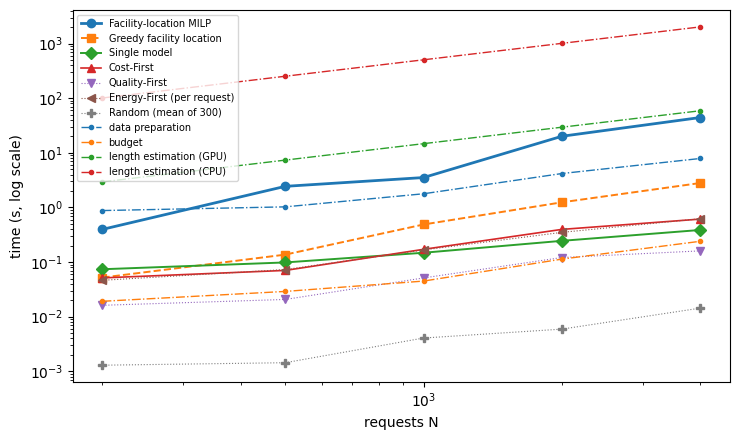

In [12]:
TIMING_PATH = "data/request_estimates/estimator_timing.json"
for old, new in PATH_REPLACEMENTS.items():
    TIMING_PATH = TIMING_PATH.replace(old, new)
e7_runs = res[(res["experiment"] == "E7") & res["ok"]].copy()
if len(e7_runs):
    e7_runs["N"] = pd.to_numeric(e7_runs["N"])
    per_method = (meth[meth["experiment"] == "E7"].merge(e7_runs[["run_id", "N"]], on="run_id")
                  .groupby(["N", "method"])["decision_time_s"].mean().unstack())
    per_method = per_method[[m for m in STYLE if m in per_method.columns]]
    per_method["data preparation"] = e7_runs.groupby("N")["preparation_s"].mean()
    per_method["budget"] = e7_runs.groupby("N")["budget_s"].mean()
    if os.path.exists(TIMING_PATH):
        est = json.load(open(TIMING_PATH))
        for device in ["gpu", "cpu"]:
            if est.get(f"{device}_ms_per_request"):
                per_method[f"length estimation ({device.upper()})"] = per_method.index * est[f"{device}_ms_per_request"] / 1e3
    print("=== Time of a decision (s), mean over the seeds")
    print(per_method.round(4).to_string())
    per_method.to_csv(os.path.join(EXP_DIR, "decision_time.csv"))
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for col in per_method.columns:
        st = STYLE.get(col, dict(color=None, marker=".", lw=1.0, ls="-."))
        ax.plot(per_method.index, per_method[col], marker=st["marker"], color=st["color"], lw=st["lw"], ls=st["ls"], label=col)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("requests N"); ax.set_ylabel("time (s, log scale)")
    ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(os.path.join(EXP_DIR, "decision_time.png"), dpi=130); plt.show()

## The models in the base cases

In [13]:
models_tab = pd.read_csv(MODELS_CSV, on_bad_lines="skip").drop_duplicates(["run_id", "model"], keep="last")
for base_n in BASE_N:
    rid = plan[(plan["experiment"] == "E7") & (plan["value"] == f"N = {base_n}") & (plan["seed"] == SEEDS[0])]["run_id"]
    if len(rid) and rid.iloc[0] in set(models_tab["run_id"]):
        print(f"\n=== Base case N = {base_n}, seed {SEEDS[0]}")
        print(models_tab[models_tab["run_id"] == rid.iloc[0]].drop(columns="run_id").set_index("model").round(4).to_string())



=== Base case N = 200, seed 42
                                           role  mean_quality  eligible_for  mean_serving_J  fixed_energy_kJ  activation_kJ  mean_cost_usd  active  requests_assigned
model                                                                                                                                                                
llama3-openbiollm-70b                  medicine        0.4433           148        240.3517         120.1728         9.3682         0.0002       0                  0
llama3-med42-70b                       medicine        0.4577           148        240.3517         120.1740         9.3957         0.0002       0                  0
llama-3.1-70b-instruct               generalist        0.5245           194        240.3517         120.1740         9.3957         0.0003       0                  0
llama-3.1-8b-instruct                generalist        0.3021            38         47.0013          30.0093         1.5718         0.0001

## Summary

In [14]:
rows = []
for exp, t in tables.items():
    for base_n in dict.fromkeys(t.index.get_level_values("base_N")):
        s = t.xs(base_n, level="base_N")
        multi = [str(v) for v, m in s["models"].items() if pd.notna(m) and m > 1.0]
        no_single = [str(v) for v, ok in s["single_ok"].items() if str(ok).startswith("0/")]
        best = s["saving_%"].idxmax() if s["saving_%"].notna().any() else None
        rows.append({"experiment": exp, "base_N": base_n,
                     "largest_saving": f"{s['saving_%'].max():.2f}% at {best}" if best is not None else "-",
                     "more_than_one_model": ", ".join(multi) if multi else "none",
                     "no_feasible_single_model": ", ".join(no_single) if no_single else "none"})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(EXP_DIR, "summary.csv"), index=False)


experiment base_N                      largest_saving                                                                                                                                           more_than_one_model  no_feasible_single_model
        E7    own                   2.37% at N = 1000                                                                                                                         N = 500, N = 1000, N = 2000, N = 4000        N = 2000, N = 4000
         P    200                        9.06% at 0 W                                                                                                                                                           0 W                      none
         P   1000                       24.06% at 0 W                                                                                                                                      0 W, 25 W, 49.9 W (base)                      none
        E1    200                        0.00% a

## Thesis figures and tables

Figures and tables of the Results chapter and of the Appendix. Run the setup cells (not the run cells) and "Results by experiment" first. Files are saved in `EXP_DIR/thesis_figures`.

In [15]:
import matplotlib as mpl
from matplotlib.lines import Line2D

FIG_DIR = os.path.join(EXP_DIR, "thesis_figures")
os.makedirs(FIG_DIR, exist_ok=True)
mpl.rcParams.update({"font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5, "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#E3E6EA", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 150, "savefig.bbox": "tight", "pdf.fonttype": 42})
TEXT_W = 6.3                                   # text width of the thesis (inches)
MILP, SINGLE = "Facility-location MILP", "Single model"
G, GREY, LIGHT = "#4D7A47", "#6B7682", "#B9C0C8"
N_SEEDS = len(SEEDS)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200)
    plt.show()

# one row per (experiment, value, base case, seed) with everything the figures need
by_method = meth.drop_duplicates(["run_id", "method"]).set_index(["run_id", "method"])
def from_method(col, method):
    s = by_method.xs(method, level="method")[col]
    return res["run_id"].map(s)

pair = res[res["ok"]].copy()
pair["milp_ok"] = pair["milp_feasible"] == 1
pair["single_ok"] = pair["single_model_feasible"] == 1
pair["both"] = pair["milp_ok"] & pair["single_ok"]
pair["fixed_share"] = 100 * (pair["activation_kJ"] + pair["parking_kJ"]) / pair["energy_kJ"]
pair["cost_milp"] = 100 * pair["cost_usd"] / pair["budget_usd"]
pair["cost_single"] = 100 * pair["single_model_cost_usd"] / pair["budget_usd"]
pair["util_milp"] = pair["max_utilisation"]
pair["util_single"] = from_method("max_utilisation", SINGLE)
pair["q_milp"] = from_method("mean_quality", MILP)
pair["q_single"] = from_method("mean_quality", SINGLE)
pair["spec_milp"] = 100 * pair["to_specialists"]
pair["saving"] = np.where(pair["both"], 100 * (pair["single_model_energy_kJ"] - pair["energy_kJ"]) / pair["single_model_energy_kJ"], np.nan)
print(f"{pair['run_id'].nunique()} runs; FL-MILP feasible in {pair.drop_duplicates('run_id')['milp_ok'].sum()}, "
      f"single model feasible in {pair.drop_duplicates('run_id')['single_ok'].sum()}")

def summary(g):
    # one point of a figure: means over the seeds in which both methods are feasible
    b, m = g[g["both"]], g[g["milp_ok"]]
    out = {"n_both": len(b), "n_milp": len(m), "n_single": int(g["single_ok"].sum()), "n": len(g),
           "E_milp": b["energy_kJ"].mean(), "E_milp_sd": b["energy_kJ"].std(),
           "E_single": b["single_model_energy_kJ"].mean(), "E_single_sd": b["single_model_energy_kJ"].std(),
           "E_milp_alone": m["energy_kJ"].mean(), "models": m["models"].mean(), "saving": b["saving"].mean(), "saving_sd": b["saving"].std()}
    for col in ["fixed_share", "cost_milp", "cost_single", "util_milp", "util_single", "q_milp", "q_single", "spec_milp"]:
        src = m if col.endswith("milp") or col in ("fixed_share",) else b
        out[col] = src[col].mean() if len(src) else np.nan
        out[col + "_b"] = b[col].mean() if len(b) else np.nan          # same paired seeds as the energies
    return pd.Series(out)

def points(exp, base_n):
    g = pair[(pair["experiment"] == exp) & (pair["base_N"] == base_n)]
    order = list(dict.fromkeys(plan.loc[plan["experiment"] == exp, "value"]))
    p = g.groupby("value", sort=False).apply(summary)
    return p.reindex([v for v in order if v in p.index])

def clean(v):
    return str(v).replace(" (base)", "")

num = lambda v: float(re.findall(r"[\d.]+", clean(v).replace(",", ""))[0])

445 runs; FL-MILP feasible in 440, single model feasible in 298


In [ ]:
# methods, colors and one row per (experiment point, seed, method)
ORDER = [MILP, "Greedy facility location", SINGLE, "Energy-First (per request)", "Cost-First", "Quality-First", "Random (mean of 300)"]
SHORT = {MILP: "FL-MILP", "Greedy facility location": "Greedy FL", SINGLE: "Single model", "Energy-First (per request)": "Energy-First",
         "Cost-First": "Cost-First", "Quality-First": "Quality-First", "Random (mean of 300)": "Random"}
mm = meth.drop_duplicates(["run_id", "method"])
mm = mm[mm["run_id"].isin(res.loc[res["ok"], "run_id"])]
runs_u = res[res["ok"]].drop_duplicates("run_id").set_index("run_id")
n_runs = len(runs_u)
feas = mm[mm["feasible"] == 1]
best = feas.groupby("run_id")["energy_kJ"].min()
no_solution = n_runs - len(best)
proven = runs_u["milp_optimal"] == 1
is_best = feas.assign(best=feas["run_id"].map(best)).query("energy_kJ <= best * (1 + 1e-6)")
share_best = is_best.groupby("method")["run_id"].nunique().reindex(ORDER).fillna(0) / n_runs * 100
share_feas = feas.groupby("method")["run_id"].nunique().reindex(ORDER).fillna(0) / n_runs * 100
not_proven = runs_u.index[(runs_u["milp_feasible"] == 1) & ~proven]
beaten = is_best[is_best["run_id"].isin(not_proven) & (is_best["method"] != MILP)]["run_id"].nunique()
print(f"{n_runs} runs; no feasible solution: {no_solution} (the FL-MILP proves it); FL-MILP not proven optimal: {len(not_proven)}, "
      f"in which a baseline is better: {beaten}")

MCOL = {MILP: G, "Greedy facility location": "#3B6FB6", SINGLE: "#C2803A", "Energy-First (per request)": "#8A63B8",
        "Cost-First": "#C24F4F", "Quality-First": "#3A9BA6", "Random (mean of 300)": "#8C8C8C"}
pts = pair[["run_id", "experiment", "value", "base_N", "seed"]].merge(
    mm[["run_id", "method", "energy_kJ", "feasible", "cost_usd", "max_utilisation", "mean_quality", "to_specialists", "models"]], on="run_id")
pts = pts.merge(mm[mm["method"] == MILP][["run_id", "energy_kJ", "feasible"]].rename(columns={"energy_kJ": "e0", "feasible": "f0"}), on="run_id")
pts = pts.merge(res[["run_id", "budget_usd"]].drop_duplicates("run_id"), on="run_id")
pts["ratio"] = np.where((pts["feasible"] == 1) & (pts["f0"] == 1), pts["energy_kJ"] / pts["e0"], np.nan)
pts["cost_B"] = 100 * pts["cost_usd"] / pts["budget_usd"]
pts["to_specialists"] = 100 * pts["to_specialists"]

445 runs; no feasible solution: 5 (the FL-MILP proves it); FL-MILP not proven optimal: 14, in which a baseline is better: 0


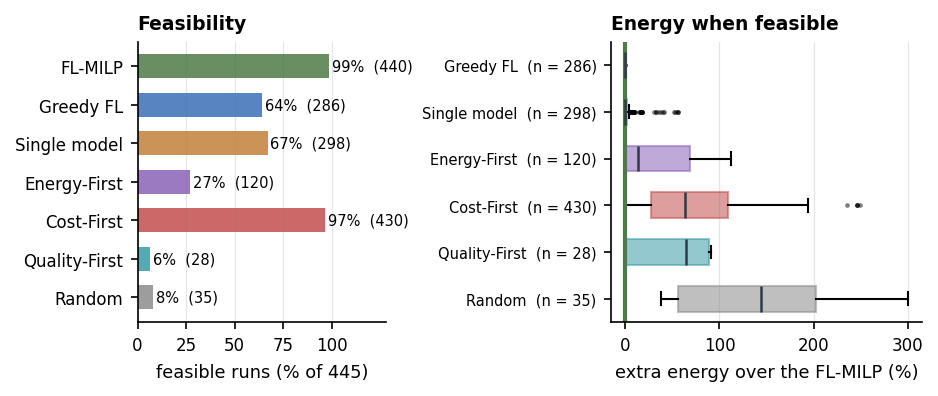

                            count    mean    std    min     50%     max
method                                                                 
Greedy facility location    286.0    0.00   0.00   0.00    0.00    0.00
Single model                298.0    3.38   9.23   0.00    0.00   55.78
Energy-First (per request)  120.0   31.70  35.57   0.00   13.03  112.42
Cost-First                  430.0   72.63  55.02  -0.00   63.06  249.23
Quality-First                28.0   48.96  38.54   0.00   64.16   91.13
Random (mean of 300)         35.0  147.99  79.99  37.94  143.77  299.92


In [ ]:
# comparison with the baselines over all runs
ext = mm.merge(mm[mm["method"] == MILP][["run_id", "feasible", "energy_kJ"]].rename(columns={"feasible": "f0", "energy_kJ": "e0"}), on="run_id")
ext = ext[(ext["feasible"] == 1) & (ext["f0"] == 1) & (ext["method"] != MILP)]
ext["extra"] = 100 * (ext["energy_kJ"] / ext["e0"] - 1)
fig, axes = plt.subplots(1, 2, figsize=(TEXT_W, 2.7), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
names = [SHORT[m] for m in ORDER][::-1]
ax.barh(names, share_feas.values[::-1], color=[MCOL[m] for m in ORDER][::-1], alpha=0.85, height=0.62)
for k, (m, v) in enumerate(zip(ORDER[::-1], share_feas.values[::-1])):
    ax.text(v + 1.5, k, f"{v:.0f}%  ({round(v * n_runs / 100)})", va="center", fontsize=7)
ax.set_xlim(0, 128); ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel(f"feasible runs (% of {n_runs})"); ax.grid(axis="y", visible=False)
ax.set_title("Feasibility", loc="left", fontweight="bold")
ax = axes[1]
data = [ext.loc[ext["method"] == m, "extra"].values for m in ORDER[1:]][::-1]
labels = [f"{SHORT[m]}  (n = {len(ext[ext['method'] == m])})" for m in ORDER[1:]][::-1]
keep = [k for k, d in enumerate(data) if len(d)]
bp = ax.boxplot([data[k] for k in keep], vert=False, widths=0.55, patch_artist=True, showfliers=True,
                flierprops={"marker": ".", "ms": 2.5, "alpha": 0.5}, medianprops={"color": "#2E3A46", "lw": 1.2})
for patch, k in zip(bp["boxes"], keep):
    m = ORDER[1:][::-1][k]
    patch.set_facecolor(MCOL[m]); patch.set_alpha(0.55); patch.set_edgecolor(MCOL[m])
ax.set_yticks(range(1, len(keep) + 1)); ax.set_yticklabels([labels[k] for k in keep], fontsize=7)
ax.axvline(0, color=G, lw=2)
ax.set_xlabel("extra energy over the FL-MILP (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Energy when feasible", loc="left", fontweight="bold")
fig.tight_layout()
save(fig, "res_baselines")
print(ext.groupby("method")["extra"].describe(percentiles=[.5]).round(2).reindex(ORDER[1:]).to_string())

In [ ]:
# experiment figures with every method: energy over the same seeds, feasible seeds, and the quantity the experiment changes
from matplotlib.colors import LinearSegmentedColormap
SOFT = LinearSegmentedColormap.from_list("soft", ["#FFFFFF", "#CFE3C8"])

def full_figure(exp, xlabel, numeric=None, extra=None, name=None, label=None, rows=None):
    # numeric: ordered parameter, drawn as lines; None: distinct scenarios, drawn as points
    # extra = (column, y label, reference line) for the third panel
    # every quantity is the mean over the SAME seeds for all methods, so all methods refer to the same batches
    # Marker: filled = feasible in every seed, half-filled = in some, hollow = in none.
    label = label or (lambda v: f"{num(v):,.10g}" if numeric else clean(v))
    if rows is None:
        rows = [(None, "own", None)] if exp in NO_BASE else [(f"N = {b:,}", b, None) for b in BASE_N]
    ncol = 3 if extra else 2
    H = 2.3 * len(rows) + 0.6
    fig, axes = plt.subplots(len(rows), ncol, figsize=(TEXT_W, H), squeeze=False, gridspec_kw={"width_ratios": [1.25, 1, 1][:ncol]})
    for row, (title, base_n, keep) in enumerate(rows):
        g = pts[(pts["experiment"] == exp) & (pts["base_N"] == base_n)]
        if keep is not None:
            g = g[g["value"].map(keep)]
        order = [v for v in dict.fromkeys(plan.loc[plan["experiment"] == exp, "value"]) if v in set(g["value"])]
        x = np.arange(len(order), dtype=float)
        lines = numeric is not None
        dodge = {m: 0 for m in ORDER} if lines else dict(zip(ORDER, np.linspace(-0.2, 0.2, len(ORDER))))
        def draw(ax, col):
            for m in ORDER[::-1]:
                gm = g[g["method"] == m].groupby("value")
                s = pd.DataFrame({"y": gm[col].mean(), "f": gm["feasible"].sum(), "n": gm.size()}).reindex(order)
                big = m == MILP
                kw = dict(color=MCOL[m], ms=5 if big else 3.6, mew=1.0, zorder=6 if big else 3)
                if lines:
                    ax.plot(x, s["y"], color=MCOL[m], lw=2.4 if big else 0.9, zorder=5 if big else 2)
                for xi, (v, r) in zip(x + dodge[m], s.iterrows()):
                    fs = "full" if r["f"] == r["n"] else ("none" if r["f"] == 0 else "left")
                    ax.plot([xi], [r["y"]], "o", fillstyle=fs, markerfacecoloralt="white", mfc=MCOL[m] if fs != "none" else "white", **kw)
            if not lines:
                ax.grid(axis="x", visible=False)
        # energy of every method, mean over all seeds
        ax = axes[row, 0]
        draw(ax, "energy_kJ")
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if str(int(round(v)))[0] in "25" else ""))
        ax.tick_params(axis="y", which="minor", labelsize=6.5)
        ax.set_ylabel("energy (kJ, log scale)")
        # feasible seeds of every method
        ax = axes[row, 1]
        F = np.array([[int(g[(g["method"] == m) & (g["value"] == v)]["feasible"].sum()) for v in order] for m in ORDER])
        N = np.array([[len(g[(g["method"] == m) & (g["value"] == v)]) for v in order] for m in ORDER])
        ax.pcolormesh(F / np.maximum(N, 1), cmap=SOFT, vmin=0, vmax=1, edgecolors="#E3E6EA", linewidth=0.6)
        ax.invert_yaxis()
        for i in range(len(ORDER)):
            for j in range(len(order)):
                ax.text(j + 0.5, i + 0.5, f"{F[i, j]}", ha="center", va="center", fontsize=6.5, color="#2E3A46" if F[i, j] else "#9AA3AD")
        ax.set_yticks(np.arange(len(ORDER)) + 0.5); ax.set_yticklabels([SHORT[m] for m in ORDER], fontsize=6.5)
        for t, m in zip(ax.get_yticklabels(), ORDER):
            t.set_color(MCOL[m])
        ax.set_xticks(np.arange(len(order)) + 0.5); ax.grid(False)
        ax.set_xticklabels([label(v) for v in order], fontsize=6.5)
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.tick_params(length=0)
        ax.set_title(f"feasible seeds (of {N.max()})", fontsize=7.5)
        # the quantity the experiment changes
        if extra:
            ax = axes[row, 2]
            col, ylab, ref = extra
            draw(ax, col)
            if ref is not None:
                ax.axhline(ref, color="#B0413E", lw=0.8, ls=":")
            ax.set_ylabel(ylab)
        for k in ([0, 2] if extra else [0]):
            a = axes[row, k]
            a.set_xticks(x); a.set_xlim(-0.5, len(order) - 0.5)
            a.set_xticklabels([label(v) for v in order], fontsize=6.5)
            for t, v in zip(a.get_xticklabels(), order):
                if "(base)" in str(v):
                    t.set_fontweight("bold")
        axes[row, 0].set_xlabel(xlabel, fontsize=7)
        if title:
            axes[row, 0].set_title(title, loc="left", fontweight="bold")
    handles = [Line2D([], [], color=MCOL[m], lw=2.4 if m == MILP else 1, marker="o", ms=3.5, label=SHORT[m]) for m in ORDER]
    fig.legend(handles=handles, loc="upper center", ncol=7, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=7, handlelength=1.5, columnspacing=1)
    marks = [Line2D([], [], color=GREY, lw=0, marker="o", ms=4, fillstyle=f, markerfacecoloralt="white", label=l)
             for f, l in [("full", "feasible in every seed"), ("left", "feasible in some seeds"), ("none", "feasible in no seed")]]
    fig.legend(handles=marks, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0 - 0.24 / H), fontsize=7, columnspacing=1.5)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.55 / H))
    save(fig, name or f"res_{exp}")

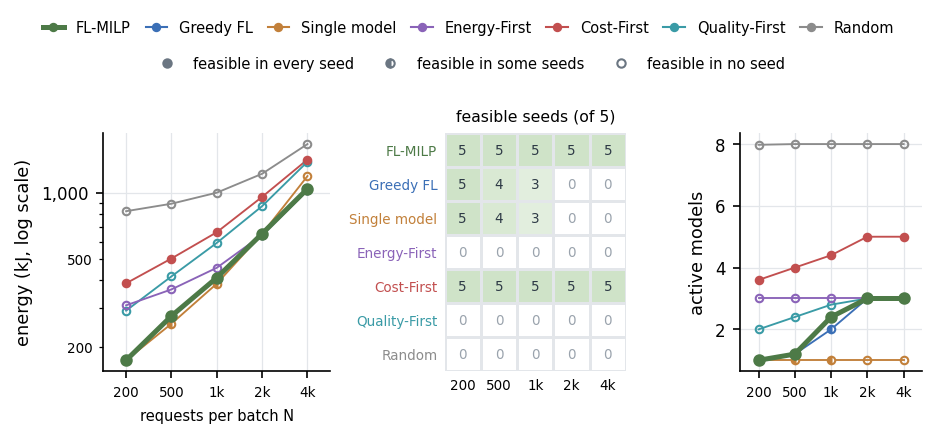

In [19]:
kfmt = lambda v: (f"{num(v) / 1000:g}k" if num(v) >= 1000 else f"{num(v):g}")
full_figure("E7", "requests per batch N", numeric=num, extra=("models", "active models", None), label=kfmt)

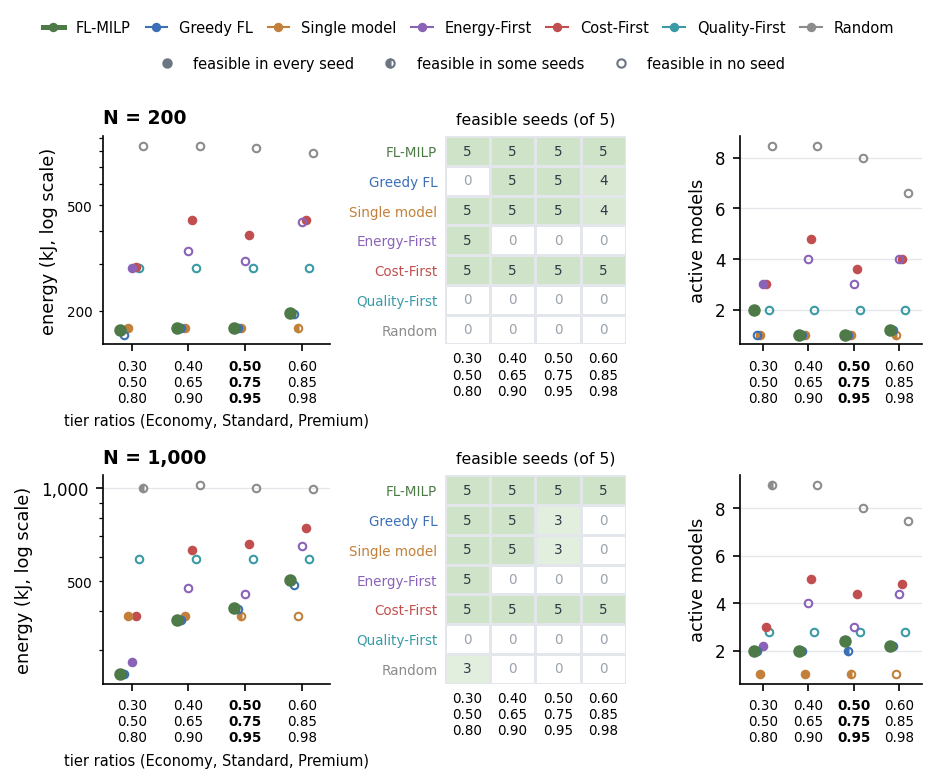

In [20]:
full_figure("E3a", "tier ratios (Economy, Standard, Premium)", extra=("models", "active models", None), label=lambda v: clean(v).replace("/", "\n"))

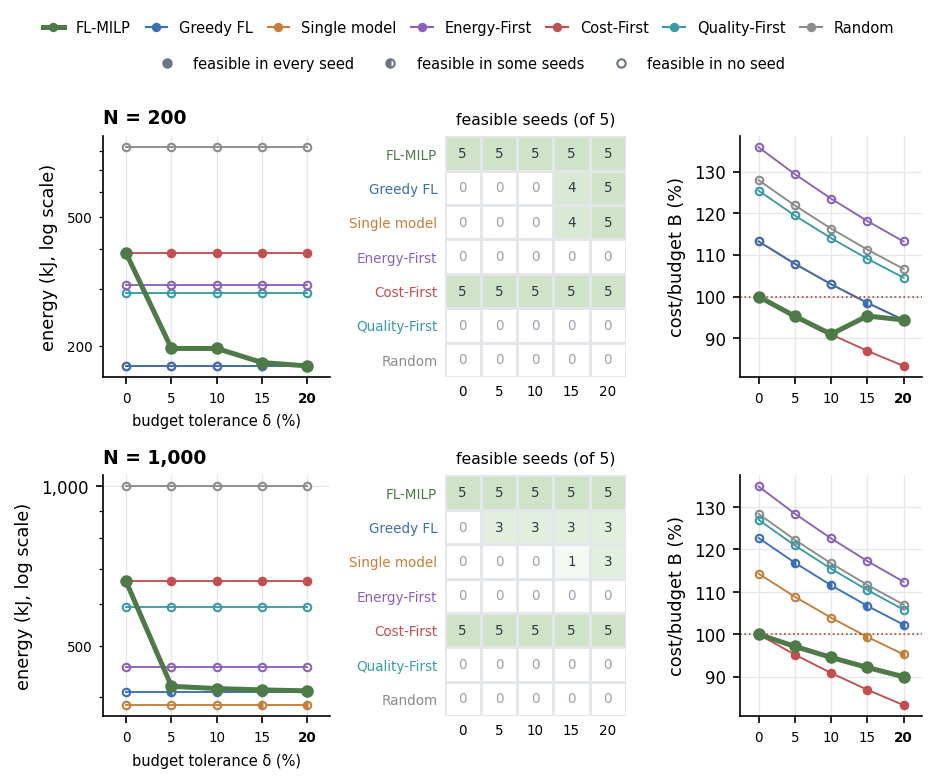

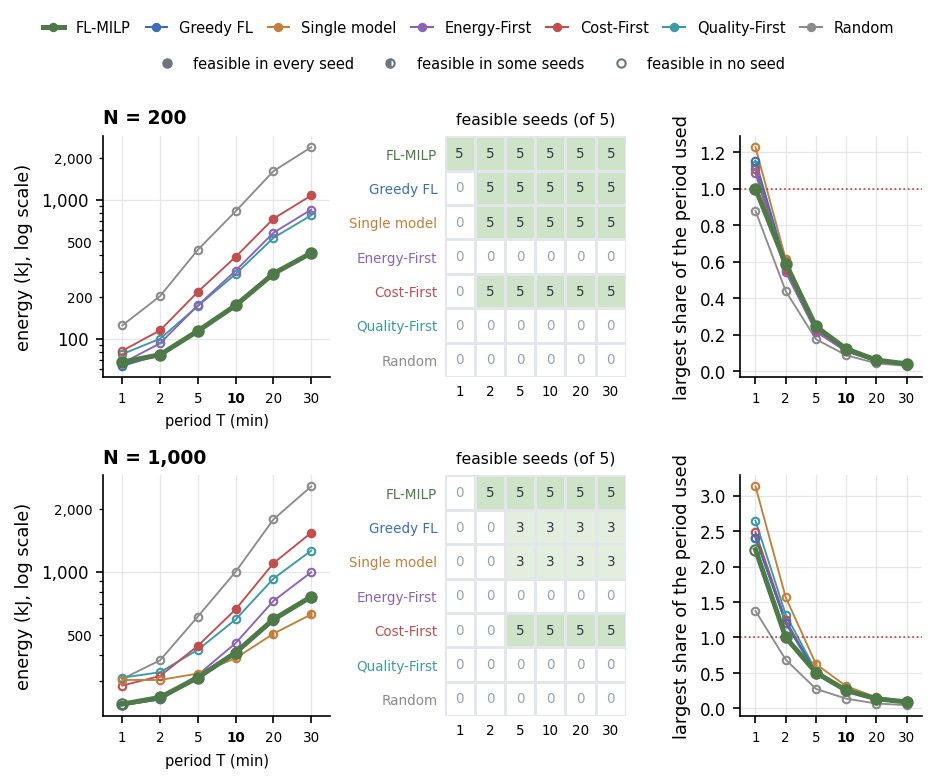

In [21]:
full_figure("E1", "budget tolerance δ (%)", numeric=num, extra=("cost_B", "cost/budget B (%)", 100))
full_figure("E2", "period T (min)", numeric=num, extra=("max_utilisation", "largest share of the period used", 1))

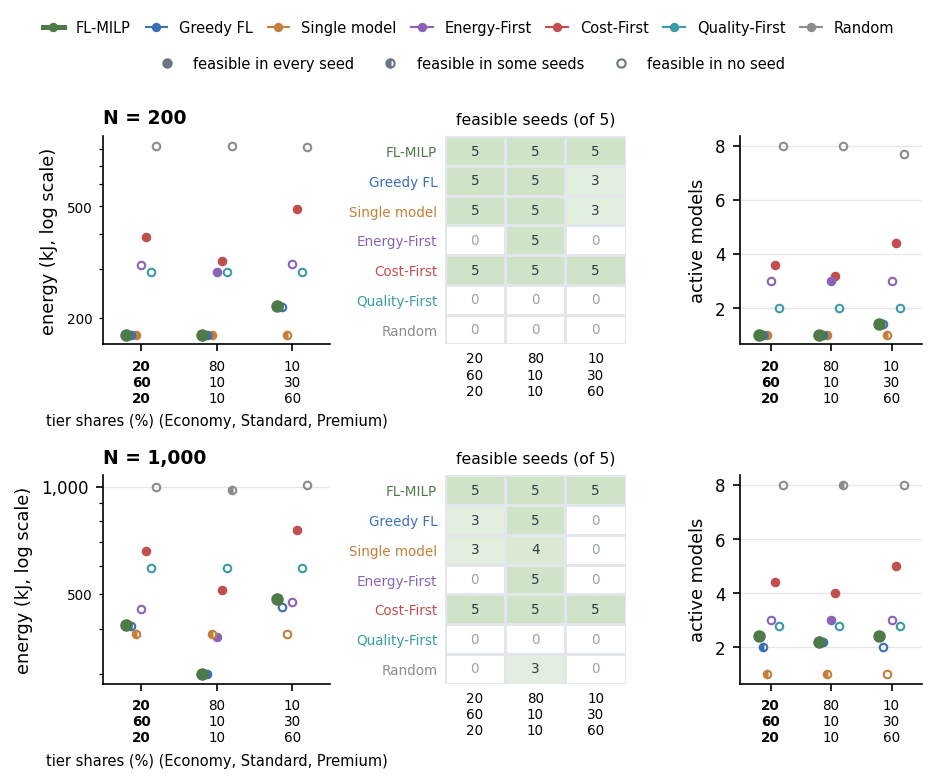

In [22]:
full_figure("E3b", "tier shares (%) (Economy, Standard, Premium)", extra=("models", "active models", None), label=lambda v: clean(v).replace("/", "\n"))

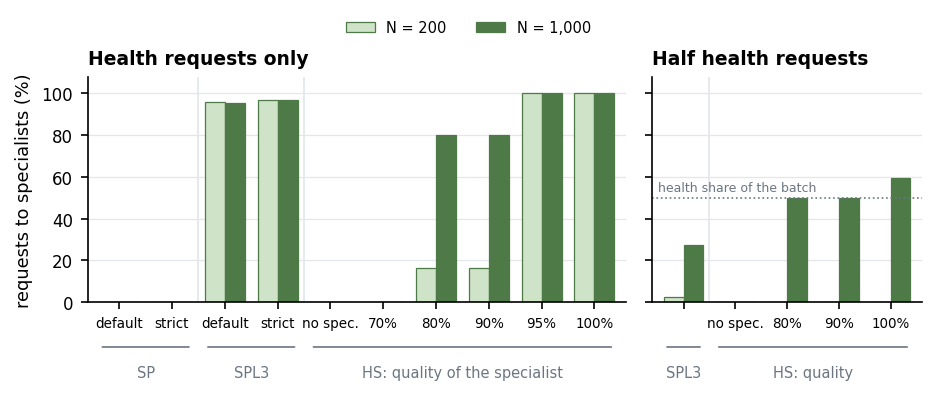

In [ ]:
# specialization: share of the requests that the FL-MILP assigns to specialists (SP, SPL3, HS)
def spec_share(exp, value, base_n):
    g = pts[(pts["experiment"] == exp) & (pts["value"] == value) & (pts["base_N"] == base_n) & (pts["method"] == MILP) & (pts["f0"] == 1)]
    return g["to_specialists"].mean()
groups = [("Health requests only", [("SP", "health, base thresholds", "default"), ("SP", "health, strict thresholds", "strict"),
                                     ("SPL3", "health, base thresholds", "default"), ("SPL3", "health, strict thresholds", "strict"),
                                     ("HS", "health only, no specialist", "no spec.")] +
                                    [("HS", f"health only, {q}% of best", f"{q}%") for q in (70, 80, 90, 95, 100)],
           [(0, 1, "SP"), (2, 3, "SPL3"), (4, 9, "HS: quality of the specialist")]),
          ("Half health requests", [("SPL3", "half health", "")] +
                                   [("HS", "half health, no specialist", "no spec.")] + [("HS", f"half health, {q}% of best", f"{q}%") for q in (80, 90, 100)],
           [(0, 0, "SPL3"), (1, 4, "HS: quality")])]
fig, axes = plt.subplots(1, 2, figsize=(TEXT_W, 2.6), gridspec_kw={"width_ratios": [10, 5]}, sharey=True)
for ax, (title, items, brackets) in zip(axes, groups):
    x = np.arange(len(items))
    for k, (base_n, colr) in enumerate([(200, "#CFE3C8"), (1000, G)]):
        vals = [spec_share(e, v, base_n) for e, v, _ in items]
        ax.bar(x + (k - 0.5) * 0.38, vals, width=0.38, color=colr, edgecolor=G, lw=0.6, label=f"N = {base_n:,}")
    ax.set_xticks(x); ax.set_xticklabels([l for _, _, l in items], fontsize=6.5)
    ax.set_xlim(-0.6, len(items) - 0.4)
    for i0, i1, lab in brackets:
        ax.annotate("", xy=(i0 - 0.4, -0.2), xytext=(i1 + 0.4, -0.2), xycoords=("data", "axes fraction"), textcoords=("data", "axes fraction"),
                    arrowprops={"arrowstyle": "-", "color": GREY, "lw": 0.8})
        ax.text((i0 + i1) / 2, -0.28, lab, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color=GREY)
    for i0, i1, _ in brackets[1:]:
        ax.axvline(i0 - 0.5, color="#E3E6EA", lw=0.8)
    ax.set_title(title, loc="left", fontweight="bold"); ax.grid(axis="x", visible=False)
    if "Half" in title:
        ax.axhline(50, color=GREY, lw=0.8, ls=":"); ax.text(-0.5, 53, "health share of the batch", ha="left", fontsize=6, color=GREY)
axes[0].set_ylabel("requests to specialists (%)"); axes[0].set_ylim(0, 108)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="upper center", ncol=2, fontsize=7, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
save(fig, "res_specialization")

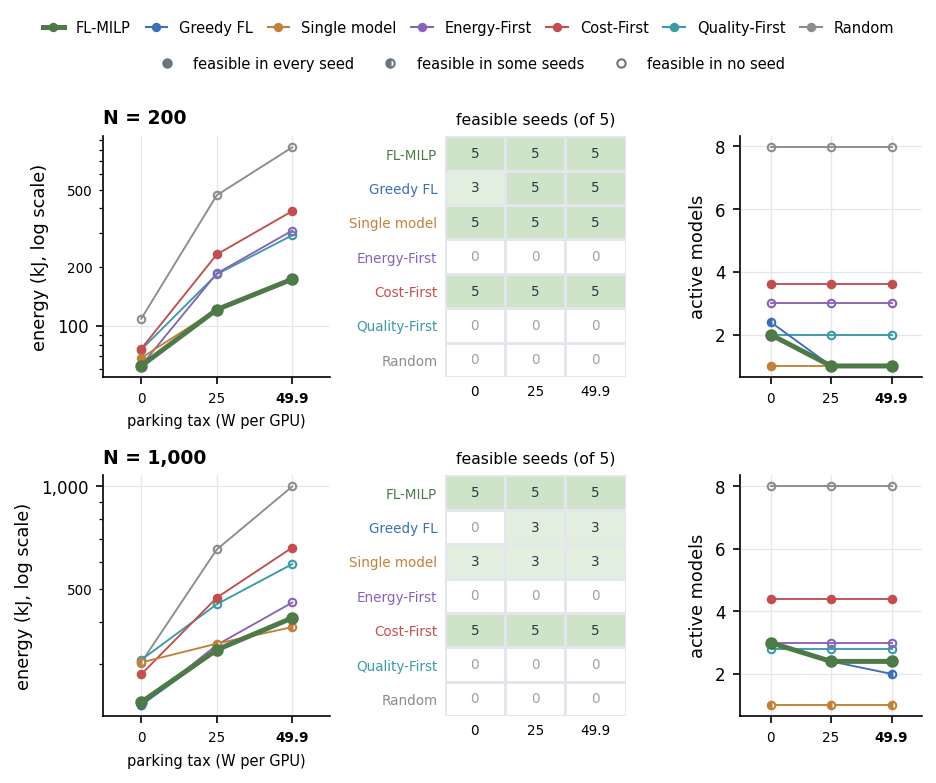

In [24]:
full_figure("P", "parking tax (W per GPU)", numeric=num, extra=("models", "active models", None))

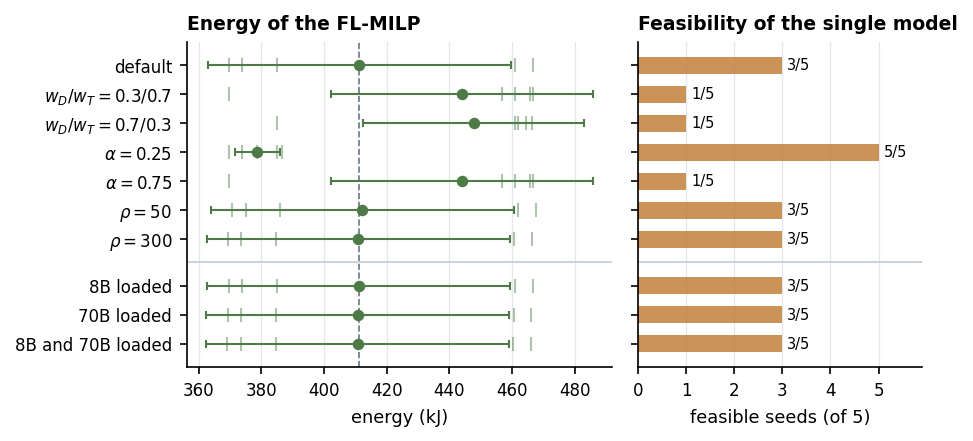

In [ ]:
# figure: sensitivity (S) and initial state (E6) at N = 1,000
# uses `pair`, `MCOL`, `SINGLE`, `G`, `GREY` and `save` from the cells above
rows_S = [("S", "base", "default"),
          ("S", "weights 0.3/0.7", "$w_D/w_T = 0.3/0.7$"), ("S", "weights 0.7/0.3", "$w_D/w_T = 0.7/0.3$"),
          ("S", "alpha 0.25", r"$\alpha = 0.25$"), ("S", "alpha 0.75", r"$\alpha = 0.75$"),
          ("S", "rho 50", r"$\rho = 50$"), ("S", "rho 300", r"$\rho = 300$"),
          ("E6", "8B", "8B loaded"), ("E6", "Llama-3.3-70B", "70B loaded"), ("E6", "both", "8B and 70B loaded")]
sel = []
for exp, val, lab in rows_S:
    d = pair[(pair["experiment"] == exp) & (pair["value"] == val) & (pair["base_N"] == 1000)].drop_duplicates("seed")
    assert len(d) == N_SEEDS, (exp, val, len(d))
    sel.append((lab, d))
y = np.arange(len(sel))[::-1].astype(float)
y[-3:] -= 0.6                                            # gap before the initial-state group
fig, axes = plt.subplots(1, 2, figsize=(TEXT_W, 3.0), gridspec_kw={"width_ratios": [1.5, 1]}, sharey=True)
ax = axes[0]
ax.axvline(sel[0][1]["energy_kJ"].mean(), color=GREY, lw=0.8, ls="--")
for (lab, d), yy in zip(sel, y):
    e = d.loc[d["milp_ok"], "energy_kJ"]
    ax.errorbar(e.mean(), yy, xerr=e.std(), fmt="o", color=G, ms=4.5, capsize=2, lw=1)
    ax.plot(e, [yy] * len(e), "|", color=G, alpha=0.45, ms=7)
ax.set_yticks(y); ax.set_yticklabels([lab for lab, _ in sel])
ax.set_xlabel("energy (kJ)"); ax.grid(axis="y", visible=False)
ax.set_title("Energy of the FL-MILP", loc="left", fontweight="bold")
ax = axes[1]
vals = [int(d["single_ok"].sum()) for _, d in sel]
ax.barh(y, vals, color=MCOL[SINGLE], alpha=0.85, height=0.6)
for v, yy in zip(vals, y):
    ax.text(v + 0.1, yy, f"{v}/{N_SEEDS}", va="center", fontsize=7)
ax.set_xlim(0, N_SEEDS + 0.9); ax.set_xticks(range(N_SEEDS + 1)); ax.set_xlabel(f"feasible seeds (of {N_SEEDS})")
ax.grid(axis="y", visible=False); ax.set_title("Feasibility of the single model", loc="left", fontweight="bold")
for a in axes:
    a.axhline((y[6] + y[7]) / 2, color="#C4CBD4", lw=0.8)
fig.tight_layout()
save(fig, "res_S")

In [ ]:
def fmt(m, sd, n, N):
    if pd.isna(m):
        return "infeasible"
    s = f"{m:,.1f} ± {sd:,.1f}" if pd.notna(sd) else f"{m:,.1f}"
    return s + (f" ({int(n)}/{int(N)})" if n < N else "")

def result_table(exps, name, spec=False):
    rows = []
    for exp in exps:
        for base_n in BASE_N:
            p = points(exp, base_n)
            for v, r in p.iterrows():
                row = {"Exp.": exp, "Configuration": clean(v), "N": f"{base_n:,}",
                       "FL-MILP (kJ)": fmt(r["E_milp"] if r["n_both"] else r["E_milp_alone"], r["E_milp_sd"] if r["n_both"] else np.nan,
                                           r["n_both"] if r["n_both"] else r["n_milp"], r["n"]),
                       "Single model (kJ)": fmt(r["E_single"], r["E_single_sd"], r["n_both"], r["n"]) if r["n_both"] else f"infeasible ({int(r['n'] - r['n_single'])}/{int(r['n'])})",
                       "Saving (%)": f"{r['saving']:.1f}" if r["n_both"] else "–",
                       "Models": f"{r['models']:.1f}" if r["n_milp"] else "–"}
                if spec:
                    row["To specialists (%)"] = f"{r['spec_milp']:.0f}" if r["n_milp"] else "–"
                rows.append(row)
    t = pd.DataFrame(rows)
    t.to_csv(os.path.join(FIG_DIR, name + ".csv"), index=False)
    latex = t.to_latex(index=False, escape=True, column_format="ll" + "r" * (len(t.columns) - 2)).replace("±", r"$\pm$")
    open(os.path.join(FIG_DIR, name + ".tex"), "w").write(latex)
    display(t) if "display" in globals() else print(t.to_string(index=False))
    return t

tab_spec = result_table(["SP", "SPL3", "HS"], "tab_app_specialization", spec=True)   # energies of the specialization experiments
tab_sens = result_table(["S"], "tab_app_S")
tab_e6 = result_table(["E6"], "tab_app_E6")
tab_bc = result_table(["BC"], "tab_app_BC")

/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)
/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)
/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and 

Exp.              Configuration     N      FL-MILP (kJ) Single model (kJ) Saving (%) Models To specialists (%)
  SP    health, base thresholds   200 136.7 ± 1.5 (4/5) 136.7 ± 1.5 (4/5)        0.0    1.2                  0
  SP  health, strict thresholds   200             266.7  infeasible (5/5)          –    2.4                  0
  SP    health, base thresholds 1,000       203.7 ± 1.3       203.7 ± 1.3        0.0    1.0                  0
  SP  health, strict thresholds 1,000             329.0  infeasible (5/5)          –    3.0                  0
SPL3    health, base thresholds   200 133.4 ± 1.2 (4/5) 133.4 ± 1.2 (4/5)        0.0    1.2                 96
SPL3  health, strict thresholds   200 133.4 ± 1.2 (4/5) 133.4 ± 1.2 (4/5)        0.0    1.2                 97
SPL3                half health   200             268.2  infeasible (5/5)          –    2.0                  2
SPL3    health, base thresholds 1,000 187.0 ± 1.2 (4/5) 187.0 ± 1.2 (4/5)        0.0    1.2                 96
S

/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)
/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)


Exp.   Configuration     N      FL-MILP (kJ) Single model (kJ) Saving (%) Models
   S            base   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
   S weights 0.3/0.7   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
   S weights 0.7/0.3   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
   S      alpha 0.25   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
   S      alpha 0.75   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
   S          rho 50   200       173.8 ± 2.4       173.8 ± 2.4        0.0    1.0
   S         rho 300   200       173.4 ± 2.4       173.4 ± 2.4        0.0    1.0
   S            base 1,000 376.2 ± 8.0 (3/5) 385.3 ± 6.4 (3/5)        2.4    2.4
   S weights 0.3/0.7 1,000       369.6 (1/5)       379.5 (1/5)        2.6    2.8
   S weights 0.7/0.3 1,000       385.0 (1/5)       392.1 (1/5)        1.8    2.8
   S      alpha 0.25 1,000       378.7 ± 7.2       386.4 ± 5.3        2.0    2.0
   S      alpha 0.75 1,000  

/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)
/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)


Exp. Configuration     N      FL-MILP (kJ) Single model (kJ) Saving (%) Models
  E6          none   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
  E6            8B   200       173.5 ± 2.4       173.5 ± 2.4        0.0    1.0
  E6 Llama-3.3-70B   200       173.1 ± 2.4       173.1 ± 2.4        0.0    1.0
  E6          both   200       173.1 ± 2.4       173.1 ± 2.4        0.0    1.0
  E6          none 1,000 376.2 ± 8.0 (3/5) 385.3 ± 6.4 (3/5)        2.4    2.4
  E6            8B 1,000 376.1 ± 8.0 (3/5) 385.3 ± 6.4 (3/5)        2.4    2.4
  E6 Llama-3.3-70B 1,000 375.7 ± 8.0 (3/5) 384.8 ± 6.4 (3/5)        2.4    2.4
  E6          both 1,000 375.7 ± 8.0 (3/5) 384.8 ± 6.4 (3/5)        2.4    2.4


/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)
/tmp/ipykernel_456/104161258.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  p = g.groupby("value", sort=False).apply(summary)


Exp. Configuration     N       FL-MILP (kJ)  Single model (kJ) Saving (%) Models
  BC            32   200        223.6 ± 4.6        223.6 ± 4.6        0.0    1.0
  BC            64   200        190.6 ± 3.1        190.6 ± 3.1        0.0    1.0
  BC           128   200        173.5 ± 2.4        173.5 ± 2.4        0.0    1.0
  BC           512   200        158.3 ± 1.7        158.3 ± 1.7        0.0    1.0
  BC            32 1,000 586.4 ± 15.5 (3/5) 634.3 ± 12.4 (3/5)        7.6    2.4
  BC            64 1,000 448.0 ± 10.6 (3/5)  470.4 ± 8.4 (3/5)        4.8    2.4
  BC           128 1,000  376.2 ± 8.0 (3/5)  385.3 ± 6.4 (3/5)        2.4    2.4
  BC           512 1,000  309.6 ± 4.6 (3/5)  309.6 ± 4.6 (3/5)        0.0    1.8


In [ ]:
# decision time against N (E7): mean over the seeds, every method
e7 = res[(res["experiment"] == "E7") & res["ok"]]
tm = mm[mm["run_id"].isin(e7["run_id"])].merge(e7[["run_id", "N"]], on="run_id")
tt = tm.pivot_table(index="method", columns="N", values="decision_time_s", aggfunc="mean").reindex(ORDER)
tt.index = [SHORT[m] for m in tt.index]
tt.loc["Data preparation"] = e7.groupby("N")["preparation_s"].mean()
tt.loc["Length estimation (CPU)"] = np.nan
tt = tt.drop(index="Length estimation (CPU)")
tt.columns = [f"N = {c:,}" for c in tt.columns]
tt_fmt = tt.map(lambda v: f"{v:.3f}" if v < 1 else f"{v:.1f}")
tt_fmt.to_csv(os.path.join(FIG_DIR, "tab_res_decision_time.csv"))
open(os.path.join(FIG_DIR, "tab_res_decision_time.tex"), "w").write(tt_fmt.to_latex(column_format="l" + "r" * tt.shape[1]))
display(tt_fmt) if "display" in globals() else print(tt_fmt.to_string())

                 N = 200 N = 500 N = 1,000 N = 2,000 N = 4,000
FL-MILP            0.397     2.4       3.5      20.1      44.3
Greedy FL          0.052   0.137     0.487       1.2       2.8
Single model       0.074   0.098     0.148     0.245     0.387
Energy-First       0.046   0.073     0.167     0.350     0.622
Cost-First         0.051   0.070     0.171     0.396     0.612
Quality-First      0.016   0.021     0.051     0.121     0.160
Random             0.001   0.001     0.004     0.006     0.014
Data preparation   0.877     1.0       1.8       4.2       7.9
